# Olist Project - Phase 3: Exploratory Data Analysis (EDA)
Put this notebook and the 8 `_clean.csv` files from Phase 1 in the **same folder**, then run the cells top to bottom.
Goal: understand **why orders are late** and decide which columns can be used as features in the ML phase.

## Section 0: Setup and building one table (one row per delivered order)

**What:** Import the libraries and set a clean chart style.
**Why:** pandas for tables, numpy for maths, matplotlib/seaborn for charts.
**Watch out:** nothing, this is only setup.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)

**What:** Load the 8 clean files from Phase 1 (dates are read as dates).
**Why:** We need every table to build the order-level table.
**Watch out:** the file names must match exactly the ones Phase 1 created.

In [4]:
from pathlib import Path

data_path = Path(
    r'C:\Users\Ankur singh patel\OneDrive\Desktop\Brazillian E-Commerce Project\data_clean'
)

customers = pd.read_csv(data_path / 'customers_clean.csv')
sellers = pd.read_csv(data_path / 'sellers_clean.csv')
geolocation = pd.read_csv(data_path / 'geolocation_clean.csv')
products = pd.read_csv(data_path / 'products_clean.csv')

orders = pd.read_csv(
    data_path / 'orders_clean.csv',
    parse_dates=[
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
)

items = pd.read_csv(
    data_path / 'order_items_clean.csv',
    parse_dates=['shipping_limit_date']
)

payments = pd.read_csv(data_path / 'order_payments_clean.csv')
reviews = pd.read_csv(data_path / 'order_reviews_clean.csv')

print(orders.shape, items.shape, payments.shape, reviews.shape)

(99441, 8) (112650, 7) (103886, 5) (98673, 5)


**What:** Keep only delivered orders with a delivery date and create the target `is_late`.
**Why:** Canceled or in-transit orders have no delivery result. Same definition as SQL: late = delivery DATE after promised DATE.
**Watch out:** expected 96,470 orders and 6,534 late (6.77%), same as the SQL phase.

In [5]:
df = orders[(orders['order_status'] == 'delivered') & (orders['order_delivered_customer_date'].notnull())].copy()

df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['estimated_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['delay_days'] = (df['order_delivered_customer_date'].dt.normalize() - df['order_estimated_delivery_date'].dt.normalize()).dt.days
df['is_late'] = (df['delay_days'] > 0).astype(int)

print(df.shape)
print('late orders:', df['is_late'].sum(), ' late %:', round(df['is_late'].mean() * 100, 2))

(96470, 12)
late orders: 6534  late %: 6.77


**What:** Add the time taken by each delivery stage (approval, waiting for pickup, transit).
**Why:** To see in which stage late orders lose their time.
**Watch out:** a few orders have impossible dates (negative stage time). We keep them here and handle them in section 5.

In [6]:
df['purchase_to_approval'] = (df['order_approved_at'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['approval_to_pickup'] = (df['order_delivered_carrier_date'] - df['order_approved_at']).dt.total_seconds() / 86400
df['pickup_to_customer'] = (df['order_delivered_customer_date'] - df['order_delivered_carrier_date']).dt.total_seconds() / 86400

df[['purchase_to_approval', 'approval_to_pickup', 'pickup_to_customer']].describe().round(2)

,purchase_to_approval,approval_to_pickup,pickup_to_customer
count,96456.00,96455.00,96469.00
mean,0.43,2.80,9.33
std,0.86,3.54,8.76
min,0.00,-171.22,-16.10
25%,0.01,0.87,4.10
50%,0.01,1.82,7.10
75%,0.60,3.57,12.03
max,30.89,125.76,205.19


**What:** Add purchase month, weekday (0 = Monday) and hour.
**Why:** Needed for the time-pattern analysis.
**Watch out:** these come from the purchase time, which is known when the order is placed (safe for ML).

In [7]:
df['purchase_month'] = df['order_purchase_timestamp'].dt.strftime('%Y-%m')
df['purchase_weekday'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour

df[['purchase_month', 'purchase_weekday', 'purchase_hour']].head()

,purchase_month,purchase_weekday,purchase_hour
0,2017-10,0,10
1,2018-07,1,20
2,2018-08,2,8
3,2017-11,5,19
4,2018-02,1,21


**What:** Summarise order_items to one row per order (items, sellers, total price, freight, weight, earliest shipping limit).
**Why:** An order has many item rows. Summing first and joining after keeps one row per order (no join explosion, same lesson as SQL).
**Watch out:** weight is the sum over all items in the order.

In [8]:
items_products = items.merge(products[['product_id', 'product_weight_g', 'product_category_name_english']], on='product_id', how='left')

items_agg = items_products.groupby('order_id').agg(
    items=('order_item_id', 'count'),
    sellers=('seller_id', 'nunique'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_weight_g=('product_weight_g', 'sum'),
    first_shipping_limit=('shipping_limit_date', 'min')
).reset_index()

print(items_agg.shape)
items_agg.head()

(98666, 7)


,order_id,items,sellers,total_price,total_freight,total_weight_g,first_shipping_limit
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29,650.0,2017-09-19 09:45:35
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93,30000.0,2017-05-03 11:05:13
2,000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87,3050.0,2018-01-18 14:48:30
3,00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79,200.0,2018-08-15 10:10:18
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14,3750.0,2017-02-13 13:57:51


**What:** Find the main category and main seller of each order (the first item).
**Why:** An order can have several categories/sellers, so we use the first item as the main one.
**Watch out:** only about 1.3% of orders have more than one seller, so this is a small simplification.

In [9]:
first_item = items_products[items_products['order_item_id'] == 1][['order_id', 'seller_id', 'product_category_name_english']]
first_item = first_item.rename(columns={'product_category_name_english': 'category'})
first_item = first_item.merge(sellers[['seller_id', 'seller_state', 'seller_zip_code_prefix']], on='seller_id', how='left')

print(first_item.shape)
first_item.head()

(98666, 5)


,order_id,seller_id,category,seller_state,seller_zip_code_prefix
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,cool_stuff,SP,27277
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,pet_shop,SP,3471
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,furniture_decor,MG,37564
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,perfumery,SP,14403
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,garden_tools,PR,87900


**What:** Summarise payments to one row per order (total paid, max installments, first payment type).
**Why:** One order can have several payment rows (for example voucher + card).
**Watch out:** same reason as items, summarise first and join after.

In [10]:
payments_agg = payments.groupby('order_id').agg(
    total_paid=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max')
).reset_index()

first_payment = payments[payments['payment_sequential'] == 1][['order_id', 'payment_type']]

print(payments_agg.shape, first_payment.shape)

(99440, 3) (99360, 2)


**What:** Join everything to the delivered-orders table (items, first item, payments, review, customer).
**Why:** Gives one table with one row per delivered order.
**Watch out:** all joins are LEFT joins and every right table has one row per order, so the row count must stay 96,470.

In [11]:
df = df.merge(items_agg, on='order_id', how='left')
df = df.merge(first_item, on='order_id', how='left')
df = df.merge(payments_agg, on='order_id', how='left')
df = df.merge(first_payment, on='order_id', how='left')
df = df.merge(reviews[['order_id', 'review_score']], on='order_id', how='left')
df = df.merge(customers[['customer_id', 'customer_state', 'customer_zip_code_prefix']], on='customer_id', how='left')

print(df.shape, ' unique orders:', df['order_id'].nunique())

(96470, 34)  unique orders: 96470


**What:** Add the coordinates of the customer zip and the seller zip.
**Why:** Needed to calculate the distance between seller and customer.
**Watch out:** some zips are missing in geolocation, so those orders get empty coordinates (counted later).

In [12]:
geo_customer = geolocation[['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng']]
geo_customer = geo_customer.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix', 'geolocation_lat': 'cust_lat', 'geolocation_lng': 'cust_lng'})

geo_seller = geolocation[['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng']]
geo_seller = geo_seller.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix', 'geolocation_lat': 'sell_lat', 'geolocation_lng': 'sell_lng'})

df = df.merge(geo_customer, on='customer_zip_code_prefix', how='left')
df = df.merge(geo_seller, on='seller_zip_code_prefix', how='left')

print(df.shape, ' rows without distance data:', df['cust_lat'].isnull().sum() + df['sell_lat'].isnull().sum())

(96470, 38)  rows without distance data: 487


**What:** Calculate the straight-line distance in km (haversine formula).
**Why:** Distance is one of the strongest expected reasons for delay.
**Watch out:** this is straight-line distance, not road distance, but it is a good proxy.

In [13]:
lat1 = np.radians(df['sell_lat'])
lat2 = np.radians(df['cust_lat'])
lng1 = np.radians(df['sell_lng'])
lng2 = np.radians(df['cust_lng'])

a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
df['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))

df['distance_km'].describe().round(1)

count    95984.0
mean       600.4
std        592.4
min          0.0
25%        185.9
50%        433.8
75%        798.3
max       3927.4
Name: distance_km, dtype: float64

**What:** Add two flags: seller and customer in the same state, and seller handed the package late to the carrier.
**Why:** Both are likely reasons for late delivery.
**Watch out:** `seller_late_handover` is known only AFTER the seller ships, so it is for understanding the problem, not for the ML model.

In [14]:
df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)
df['seller_late_handover'] = (df['order_delivered_carrier_date'].dt.normalize() > df['first_shipping_limit'].dt.normalize()).astype(int)

df[['same_state', 'seller_late_handover']].mean().round(3)

same_state              0.360
seller_late_handover    0.058
dtype: float64

## Section 1: Data overview

**What:** Check shape, data types and missing values of the new table.
**Why:** Always check the table you just built before analysing it.
**Watch out:** missing values here come from orders without items, missing zips or missing review, not from errors.

In [15]:
print(df.shape)
missing = df.isnull().sum()
missing[missing > 0]

(96470, 41)


order_approved_at                14
order_delivered_carrier_date      1
purchase_to_approval             14
approval_to_pickup               15
pickup_to_customer                1
total_paid                        1
max_installments                  1
payment_type                     79
review_score                    646
cust_lat                        272
cust_lng                        272
sell_lat                        215
sell_lng                        215
distance_km                     486
dtype: int64

**What:** Summary statistics of the main numeric columns.
**Why:** Gives min, max, average and spread of each column in one table.
**Watch out:** compare the mean with the median (50%). A big gap means a skewed column with extreme values.

In [16]:
df[['delivery_days', 'estimated_days', 'total_price', 'total_freight', 'total_weight_g', 'items', 'total_paid', 'distance_km']].describe().round(2)

,delivery_days,estimated_days,total_price,total_freight,total_weight_g,items,total_paid,distance_km
count,96470.00,96470.00,96470.00,96470.00,96470.00,96470.00,96469.00,95984.00
mean,12.56,23.74,137.04,22.79,2386.66,1.14,159.86,600.43
std,9.55,8.76,209.05,21.56,4769.74,0.54,218.82,592.39
min,0.53,2.01,0.85,0.00,2.00,1.00,9.59,0.00
25%,6.77,18.33,45.90,13.85,300.00,1.00,61.88,185.89
50%,10.22,23.23,86.50,17.17,750.00,1.00,105.28,433.84
75%,15.72,28.41,149.90,24.02,2050.00,1.00,176.33,798.31
max,209.63,155.14,13440.00,1794.96,184400.00,21.00,13664.08,3927.41


## Section 2: The target - late vs on-time

**What:** Count on-time and late orders and show the percentage.
**Why:** The model predicts this column, so we must know how imbalanced it is.
**Watch out:** only about 7% are late. A model that says "never late" would be 93% accurate and useless, so accuracy is a bad metric here.

is_late
0    89936
1     6534
Name: count, dtype: int64
is_late
0    93.23
1     6.77
Name: count, dtype: float64


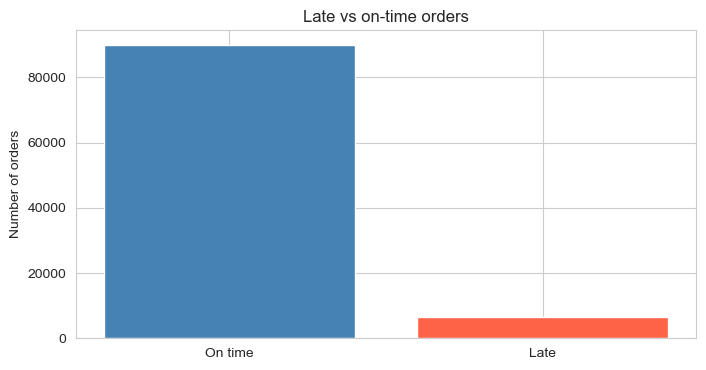

In [17]:
late_counts = df['is_late'].value_counts()
print(late_counts)
print((late_counts / len(df) * 100).round(2))

plt.bar(['On time', 'Late'], late_counts.values, color=['steelblue', 'tomato'])
plt.title('Late vs on-time orders')
plt.ylabel('Number of orders')
plt.show()

**What:** Histogram of delay_days (negative = early, positive = late).
**Why:** Shows how early most orders arrive and how big the delays are.
**Watch out:** we show only -50 to +50 days for readability; a few orders are outside this range.

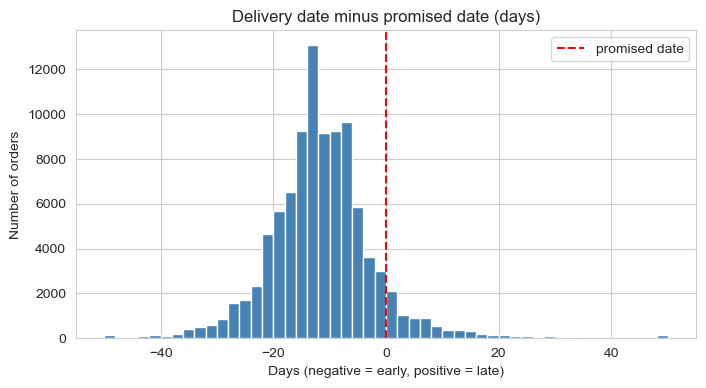

Orders delivered at least 7 days early (%): 78.9


In [18]:
plt.hist(df['delay_days'].clip(-50, 50), bins=50, color='steelblue')
plt.axvline(0, color='red', linestyle='--', label='promised date')
plt.title('Delivery date minus promised date (days)')
plt.xlabel('Days (negative = early, positive = late)')
plt.ylabel('Number of orders')
plt.legend()
plt.show()

print('Orders delivered at least 7 days early (%):', round((df['delay_days'] <= -7).mean() * 100, 1))

## Section 3: Distributions of single columns

**What:** Histograms of actual delivery days and promised delivery days.
**Why:** Compares what Olist promised with what happened.
**Watch out:** the promised time is much longer than the real time, so most orders arrive early.

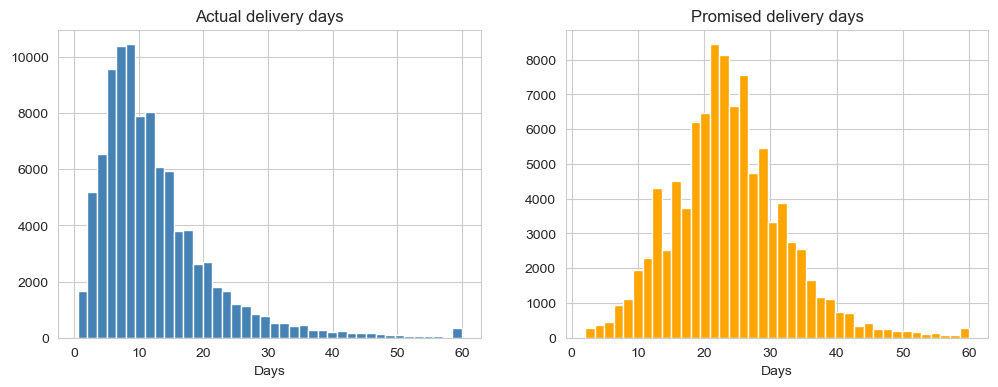

Average actual: 12.56  median actual: 10.22
Average promised: 23.74


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df['delivery_days'].clip(upper=60), bins=40, color='steelblue')
ax[0].set_title('Actual delivery days')
ax[0].set_xlabel('Days')
ax[1].hist(df['estimated_days'].clip(upper=60), bins=40, color='orange')
ax[1].set_title('Promised delivery days')
ax[1].set_xlabel('Days')
plt.show()

print('Average actual:', round(df['delivery_days'].mean(), 2), ' median actual:', round(df['delivery_days'].median(), 2))
print('Average promised:', round(df['estimated_days'].mean(), 2))

**What:** Histograms of order price and freight.
**Why:** Shows if prices are spread evenly or concentrated at low values.
**Watch out:** both are right-skewed (many small values, a few very large). We cut the chart at the 99th percentile only for display.

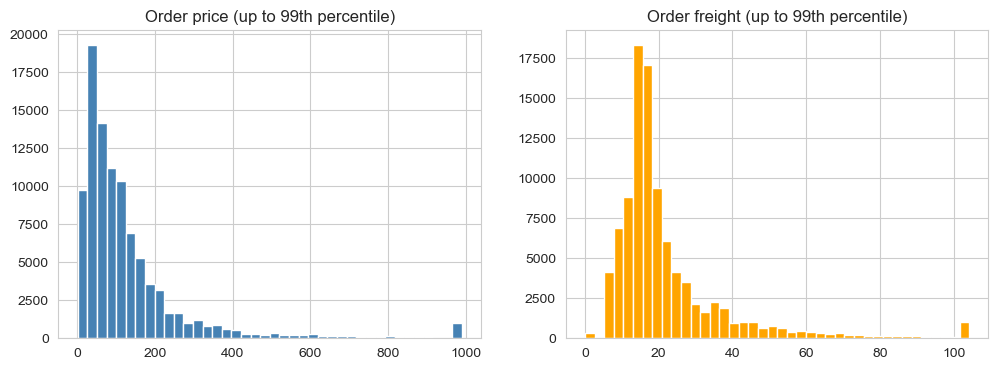

Median price: 86.5  mean price: 137.04


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df['total_price'].clip(upper=df['total_price'].quantile(0.99)), bins=40, color='steelblue')
ax[0].set_title('Order price (up to 99th percentile)')
ax[1].hist(df['total_freight'].clip(upper=df['total_freight'].quantile(0.99)), bins=40, color='orange')
ax[1].set_title('Order freight (up to 99th percentile)')
plt.show()

print('Median price:', df['total_price'].median(), ' mean price:', round(df['total_price'].mean(), 2))

**What:** Histogram of total order weight and a bar chart of items per order.
**Why:** Checks how heavy orders are and how many items a typical order has.
**Watch out:** most orders have a single item. Weight is also very skewed.

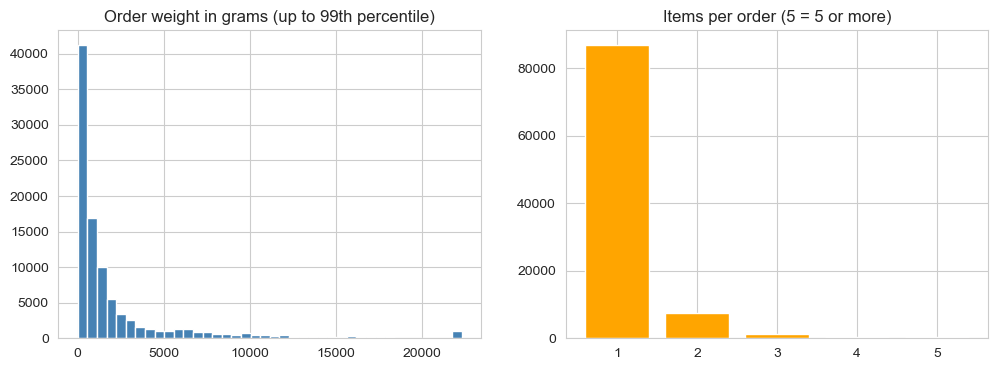

items
1    90.0
2     7.7
3     1.4
Name: proportion, dtype: float64


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df['total_weight_g'].clip(upper=df['total_weight_g'].quantile(0.99)), bins=40, color='steelblue')
ax[0].set_title('Order weight in grams (up to 99th percentile)')
items_count = df['items'].clip(upper=5).value_counts().sort_index()
ax[1].bar(items_count.index.astype(str), items_count.values, color='orange')
ax[1].set_title('Items per order (5 = 5 or more)')
plt.show()

print((df['items'].value_counts(normalize=True).head(3) * 100).round(1))

**What:** Bar charts of payment installments and review scores.
**Why:** Shows how customers pay and how satisfied they are.
**Watch out:** review scores are U-shaped (many 5s, a big block of 1s, few 2s).

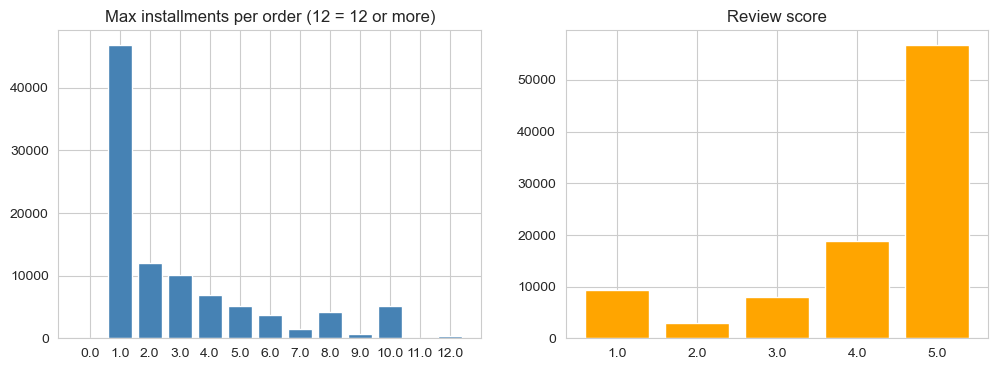

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
inst = df['max_installments'].clip(upper=12).value_counts().sort_index()
ax[0].bar(inst.index.astype(str), inst.values, color='steelblue')
ax[0].set_title('Max installments per order (12 = 12 or more)')
score = df['review_score'].value_counts().sort_index()
ax[1].bar(score.index.astype(str), score.values, color='orange')
ax[1].set_title('Review score')
plt.show()

## Section 4: Outliers (we look, explain, and do NOT remove)

**What:** Boxplots of price, freight, weight and delivery days.
**Why:** The dots outside the box are the outliers. We want to know how many there are and if they look real.
**Watch out:** the scales are different, so each column has its own chart.

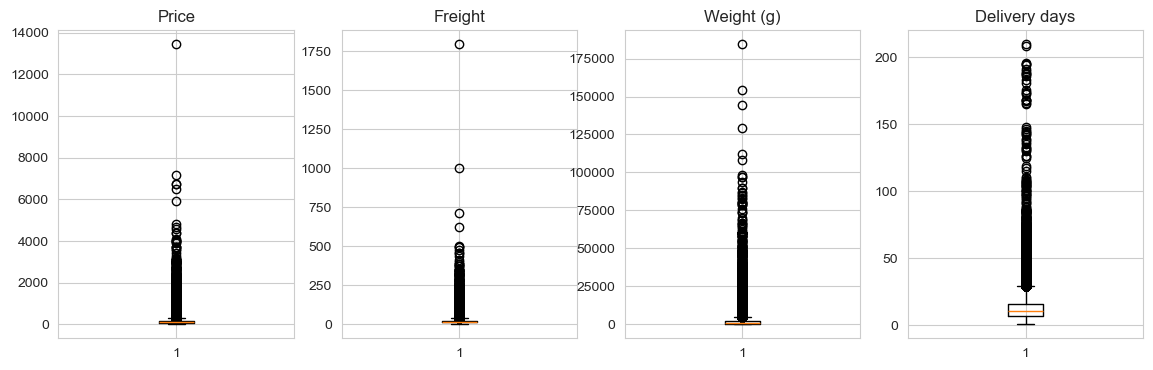

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
ax[0].boxplot(df['total_price'])
ax[0].set_title('Price')
ax[1].boxplot(df['total_freight'])
ax[1].set_title('Freight')
ax[2].boxplot(df['total_weight_g'].dropna())
ax[2].set_title('Weight (g)')
ax[3].boxplot(df['delivery_days'])
ax[3].set_title('Delivery days')
plt.show()

**What:** Count outliers with the IQR rule and compare the late rate of extreme orders with normal ones.
**Why:** If extreme orders are late much more often, they carry information and must stay in the data.
**Watch out:** we do not delete outliers. Expensive and heavy orders are real purchases.

In [24]:
price_limit = df['total_price'].quantile(0.75) + 1.5 * (df['total_price'].quantile(0.75) - df['total_price'].quantile(0.25))
freight_limit = df['total_freight'].quantile(0.75) + 1.5 * (df['total_freight'].quantile(0.75) - df['total_freight'].quantile(0.25))
weight_limit = df['total_weight_g'].quantile(0.75) + 1.5 * (df['total_weight_g'].quantile(0.75) - df['total_weight_g'].quantile(0.25))

print('Price outliers:', (df['total_price'] > price_limit).sum(), ' late % outliers:', round(df[df['total_price'] > price_limit]['is_late'].mean() * 100, 2), ' late % others:', round(df[df['total_price'] <= price_limit]['is_late'].mean() * 100, 2))
print('Freight outliers:', (df['total_freight'] > freight_limit).sum(), ' late % outliers:', round(df[df['total_freight'] > freight_limit]['is_late'].mean() * 100, 2), ' late % others:', round(df[df['total_freight'] <= freight_limit]['is_late'].mean() * 100, 2))
print('Weight outliers:', (df['total_weight_g'] > weight_limit).sum(), ' late % outliers:', round(df[df['total_weight_g'] > weight_limit]['is_late'].mean() * 100, 2), ' late % others:', round(df[df['total_weight_g'] <= weight_limit]['is_late'].mean() * 100, 2))

Price outliers: 7658  late % outliers: 8.08  late % others: 6.66
Freight outliers: 9694  late % outliers: 8.5  late % others: 6.58
Weight outliers: 13544  late % outliers: 7.67  late % others: 6.63


**What:** Scatter plot of price against freight (a random sample of 5,000 orders).
**Why:** Checks if expensive orders also have expensive freight, and spots strange points.
**Watch out:** a sample is used only so the chart is fast and readable.

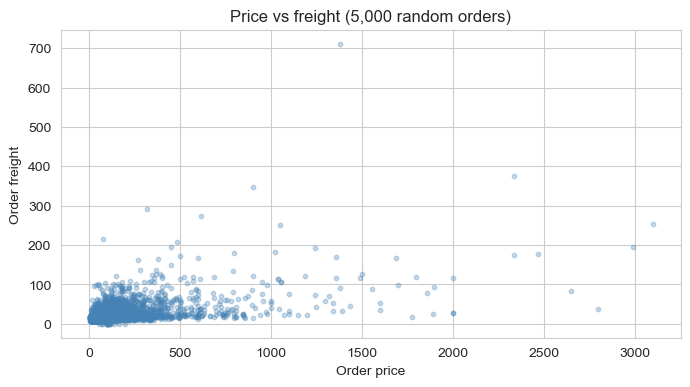

In [25]:
sample = df.sample(5000, random_state=42)

plt.scatter(sample['total_price'], sample['total_freight'], alpha=0.3, s=10, color='steelblue')
plt.title('Price vs freight (5,000 random orders)')
plt.xlabel('Order price')
plt.ylabel('Order freight')
plt.show()

## Section 5: Where does the delay happen?

**What:** Average days spent in each stage, for late and on-time orders.
**Why:** Shows whether the delay comes from the seller (approval, pickup) or from the carrier (transit).
**Watch out:** we leave out the few orders with impossible dates (negative stage time).

Orders used: 95082  removed for this chart only: 1388
         purchase_to_approval  approval_to_pickup  pickup_to_customer
On time                  0.39                2.65                8.00
Late                     0.50                5.57               27.88


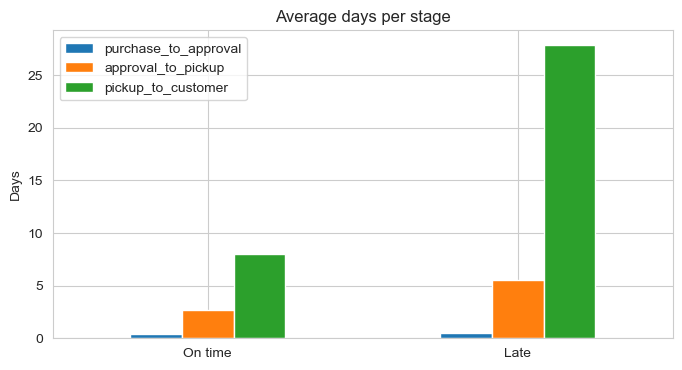

In [26]:
df_stage = df[(df['purchase_to_approval'] >= 0) & (df['approval_to_pickup'] >= 0) & (df['pickup_to_customer'] >= 0)]
print('Orders used:', len(df_stage), ' removed for this chart only:', len(df) - len(df_stage))

stage_mean = df_stage.groupby('is_late')[['purchase_to_approval', 'approval_to_pickup', 'pickup_to_customer']].mean().round(2)
stage_mean.index = ['On time', 'Late']
print(stage_mean)

stage_mean.plot(kind='bar', figsize=(8, 4))
plt.title('Average days per stage')
plt.ylabel('Days')
plt.xticks(rotation=0)
plt.show()

**What:** Boxplot of the transit time (pickup to customer) for late and on-time orders.
**Why:** The average can hide the spread. The box shows the typical range.
**Watch out:** the extreme dots are hidden to keep the chart readable.

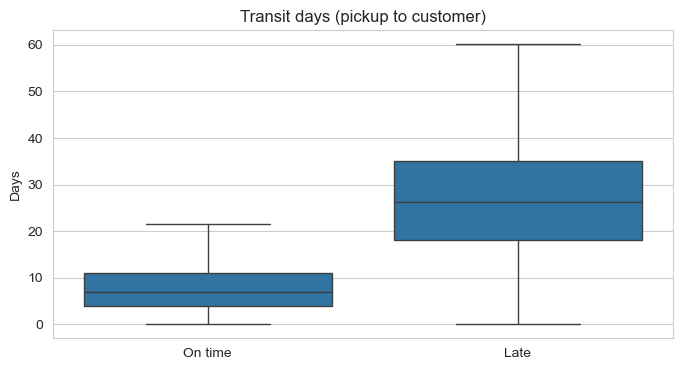

In [27]:
sns.boxplot(x='is_late', y='pickup_to_customer', data=df_stage, showfliers=False)
plt.xticks([0, 1], ['On time', 'Late'])
plt.title('Transit days (pickup to customer)')
plt.xlabel('')
plt.ylabel('Days')
plt.show()

**What:** Share of orders where the seller handed the package to the carrier after the shipping limit date, for late and on-time orders.
**Why:** Tests if slow sellers cause late deliveries.
**Watch out:** this flag exists only after shipping, so it explains the problem but cannot be an ML feature.

is_late
0     4.57
1    22.34
Name: seller_late_handover, dtype: float64


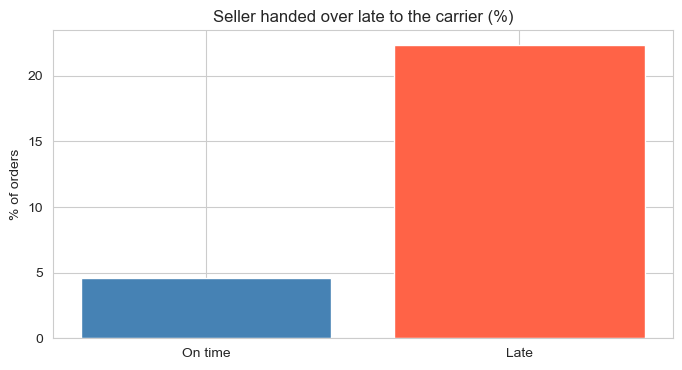

In [28]:
handover = df.groupby('is_late')['seller_late_handover'].mean() * 100
print(handover.round(2))

plt.bar(['On time', 'Late'], handover.values, color=['steelblue', 'tomato'])
plt.title('Seller handed over late to the carrier (%)')
plt.ylabel('% of orders')
plt.show()

## Section 6: Late rate by feature

**What:** Late % for each customer state with a line for the overall late rate.
**Why:** Finds regions with delivery problems.
**Watch out:** very small states can show odd percentages, check the order counts printed below.

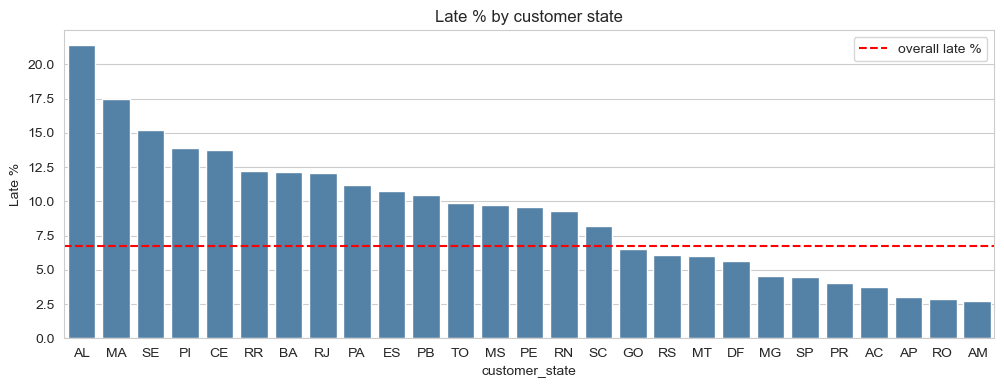

,count,late_pct
customer_state,,
AL,397,21.41
MA,717,17.43
SE,335,15.22
PI,476,13.87
CE,1279,13.76
RR,41,12.20
BA,3256,12.16
RJ,12350,12.11


In [29]:
state_late = df.groupby('customer_state')['is_late'].agg(['count', 'mean'])
state_late['late_pct'] = state_late['mean'] * 100
state_late = state_late.sort_values('late_pct', ascending=False)

plt.figure(figsize=(12, 4))
sns.barplot(x=state_late.index, y=state_late['late_pct'], color='steelblue')
plt.axhline(df['is_late'].mean() * 100, color='red', linestyle='--', label='overall late %')
plt.title('Late % by customer state')
plt.ylabel('Late %')
plt.legend()
plt.show()

state_late[['count', 'late_pct']].round(2).head(8)

**What:** Late % by seller state (states with at least 100 orders).
**Why:** Shows if the origin of the package matters.
**Watch out:** a minimum of 100 orders avoids unreliable percentages.

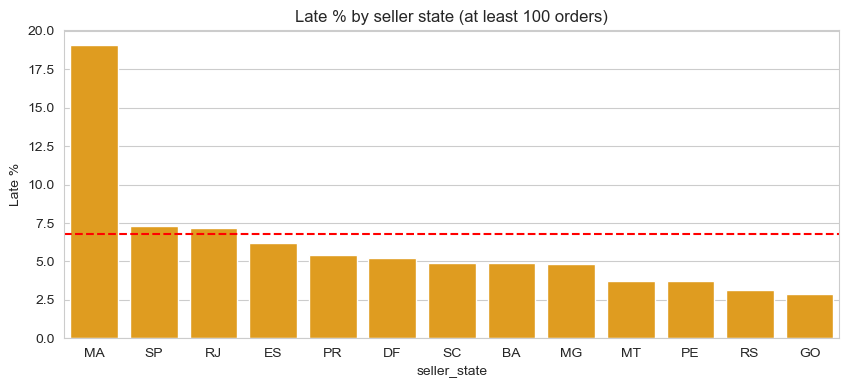

In [30]:
seller_state_late = df.groupby('seller_state')['is_late'].agg(['count', 'mean'])
seller_state_late = seller_state_late[seller_state_late['count'] >= 100]
seller_state_late['late_pct'] = seller_state_late['mean'] * 100
seller_state_late = seller_state_late.sort_values('late_pct', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(x=seller_state_late.index, y=seller_state_late['late_pct'], color='orange')
plt.axhline(df['is_late'].mean() * 100, color='red', linestyle='--')
plt.title('Late % by seller state (at least 100 orders)')
plt.ylabel('Late %')
plt.show()

**What:** Late % and average delivery days when seller and customer are in the same state or not.
**Why:** A simple first test of the distance effect.
**Watch out:** same_state is known at purchase time, so it is a safe ML feature.

                 orders  late_pct  avg_days
Different state   61769      8.05     15.15
Same state        34701      4.50      7.95


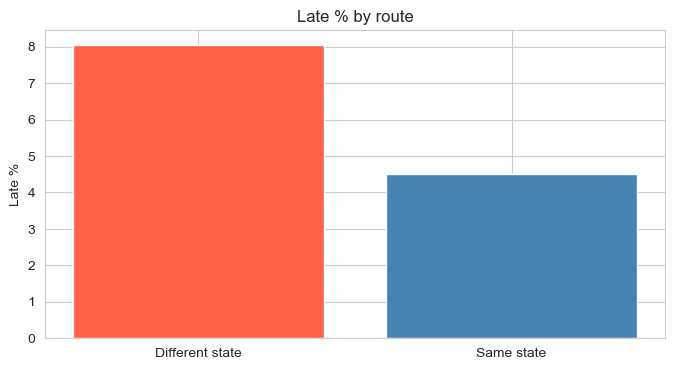

In [31]:
same = df.groupby('same_state').agg(orders=('is_late', 'count'), late_pct=('is_late', 'mean'), avg_days=('delivery_days', 'mean'))
same['late_pct'] = same['late_pct'] * 100
same.index = ['Different state', 'Same state']
print(same.round(2))

plt.bar(same.index, same['late_pct'], color=['tomato', 'steelblue'])
plt.title('Late % by route')
plt.ylabel('Late %')
plt.show()

**What:** Late % for the 10 product categories with the highest late rate (at least 300 orders).
**Why:** Some products ship slower (size, fragile, special sellers).
**Watch out:** a minimum of 300 orders keeps the percentages reliable.

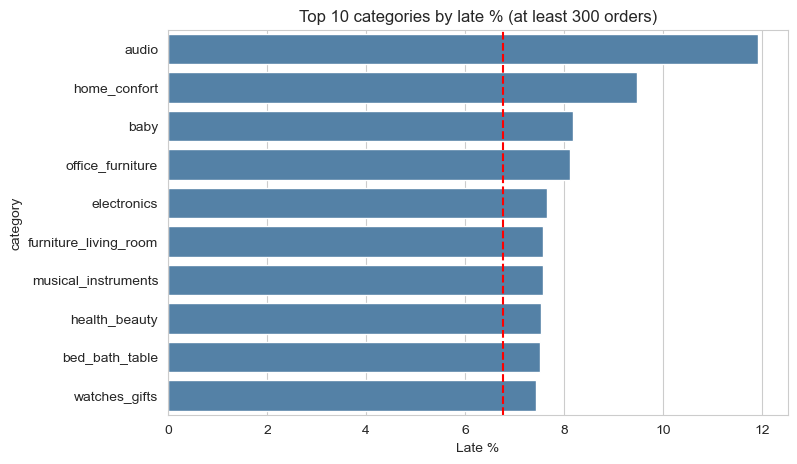

In [32]:
cat_late = df.groupby('category')['is_late'].agg(['count', 'mean'])
cat_late = cat_late[cat_late['count'] >= 300]
cat_late['late_pct'] = cat_late['mean'] * 100
cat_late = cat_late.sort_values('late_pct', ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=cat_late['late_pct'], y=cat_late.index, color='steelblue')
plt.axvline(df['is_late'].mean() * 100, color='red', linestyle='--')
plt.title('Top 10 categories by late % (at least 300 orders)')
plt.xlabel('Late %')
plt.show()

**What:** Late % by price group and by freight group.
**Why:** Checks if expensive orders or expensive shipping are delivered later.
**Watch out:** groups are made with pd.cut using fixed limits so they are easy to explain.

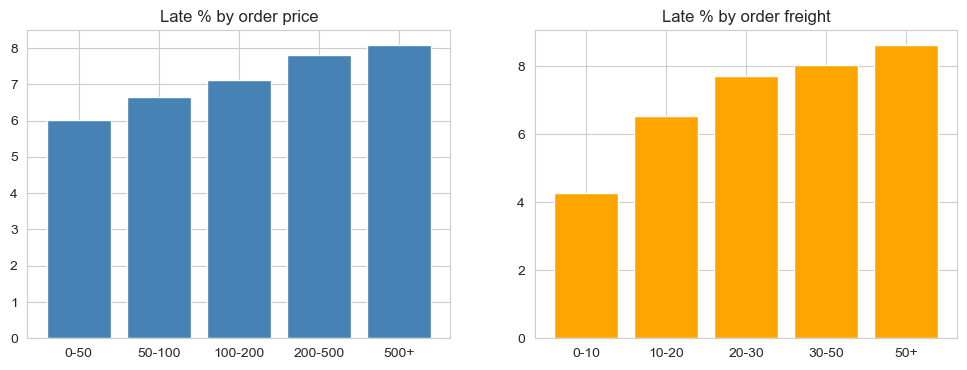

price_group
0-50       6.03
50-100     6.66
100-200    7.12
200-500    7.81
500+       8.08
Name: is_late, dtype: float64
freight_group
0-10     4.26
10-20    6.54
20-30    7.71
30-50    8.04
50+      8.61
Name: is_late, dtype: float64


In [33]:
df['price_group'] = pd.cut(df['total_price'], bins=[0, 50, 100, 200, 500, 100000], labels=['0-50', '50-100', '100-200', '200-500', '500+'])
df['freight_group'] = pd.cut(df['total_freight'], bins=[-1, 10, 20, 30, 50, 10000], labels=['0-10', '10-20', '20-30', '30-50', '50+'])

price_late = df.groupby('price_group', observed=True)['is_late'].mean() * 100
freight_late = df.groupby('freight_group', observed=True)['is_late'].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(price_late.index.astype(str), price_late.values, color='steelblue')
ax[0].set_title('Late % by order price')
ax[1].bar(freight_late.index.astype(str), freight_late.values, color='orange')
ax[1].set_title('Late % by order freight')
plt.show()

print(price_late.round(2))
print(freight_late.round(2))

**What:** Late % by order weight group and by number of items.
**Why:** Heavy or multi-item orders may need more handling.
**Watch out:** the effect of weight is small compared with distance, so do not over-claim it.

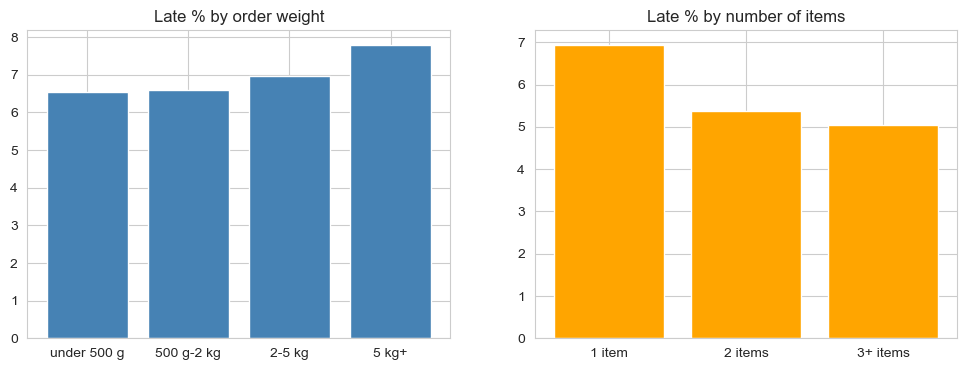

weight_group
under 500 g    6.53
500 g-2 kg     6.60
2-5 kg         6.96
5 kg+          7.79
Name: is_late, dtype: float64
items_group
1    6.94
2    5.37
3    5.04
Name: is_late, dtype: float64


In [34]:
df['weight_group'] = pd.cut(df['total_weight_g'], bins=[-1, 500, 2000, 5000, 10000000], labels=['under 500 g', '500 g-2 kg', '2-5 kg', '5 kg+'])
df['items_group'] = df['items'].clip(upper=3)

weight_late = df.groupby('weight_group', observed=True)['is_late'].mean() * 100
items_late = df.groupby('items_group')['is_late'].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(weight_late.index.astype(str), weight_late.values, color='steelblue')
ax[0].set_title('Late % by order weight')
ax[1].bar(['1 item', '2 items', '3+ items'], items_late.values, color='orange')
ax[1].set_title('Late % by number of items')
plt.show()

print(weight_late.round(2))
print(items_late.round(2))

**What:** Late % by payment type and by installments.
**Why:** Checks if the way of paying relates to late delivery.
**Watch out:** payment is made at purchase, so it cannot cause delivery delay. Any link is probably indirect (for example bigger orders use more installments).

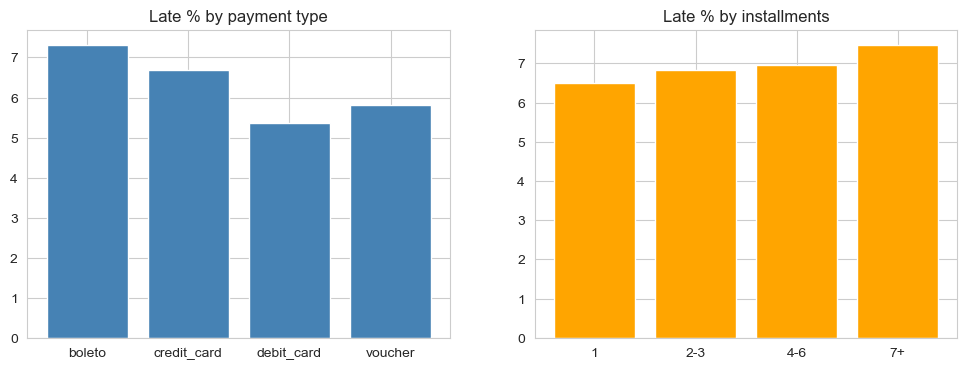

payment_type
boleto         7.32
credit_card    6.67
debit_card     5.37
voucher        5.81
Name: late_pct, dtype: float64
installments_group
1      6.51
2-3    6.83
4-6    6.95
7+     7.48
Name: is_late, dtype: float64


In [35]:
df['installments_group'] = pd.cut(df['max_installments'], bins=[0, 1, 3, 6, 100], labels=['1', '2-3', '4-6', '7+'])

pay_late = df.groupby('payment_type')['is_late'].agg(['count', 'mean'])
pay_late = pay_late[pay_late['count'] >= 100]
pay_late['late_pct'] = pay_late['mean'] * 100
inst_late = df.groupby('installments_group', observed=True)['is_late'].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(pay_late.index, pay_late['late_pct'], color='steelblue')
ax[0].set_title('Late % by payment type')
ax[1].bar(inst_late.index.astype(str), inst_late.values, color='orange')
ax[1].set_title('Late % by installments')
plt.show()

print(pay_late['late_pct'].round(2))
print(inst_late.round(2))

## Section 7: Time patterns

**What:** Orders per month and late % per month (months with at least 500 orders).
**Why:** Shows growth and the months when carriers struggled.
**Watch out:** early and last months have very few orders, so they are left out.

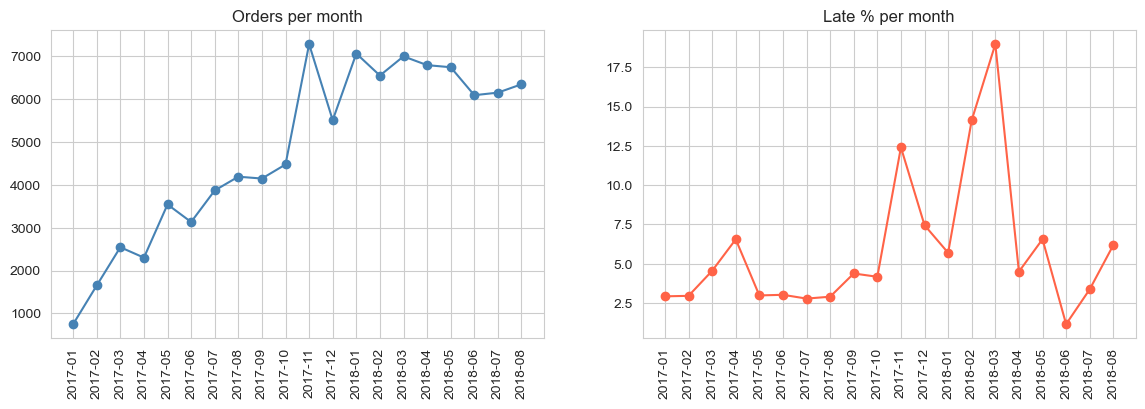

,count,late_pct
purchase_month,,
2018-03,7003,18.96
2018-02,6555,14.13
2017-11,7288,12.40
2017-12,5513,7.46
2018-05,6749,6.56


In [36]:
monthly = df.groupby('purchase_month')['is_late'].agg(['count', 'mean'])
monthly = monthly[monthly['count'] >= 500]
monthly['late_pct'] = monthly['mean'] * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(monthly.index, monthly['count'], marker='o', color='steelblue')
ax[0].set_title('Orders per month')
ax[0].tick_params(axis='x', rotation=90)
ax[1].plot(monthly.index, monthly['late_pct'], marker='o', color='tomato')
ax[1].set_title('Late % per month')
ax[1].tick_params(axis='x', rotation=90)
plt.show()

monthly.sort_values('late_pct', ascending=False)[['count', 'late_pct']].round(2).head(5)

**What:** Late % by weekday of purchase and by hour of purchase.
**Why:** Orders placed on weekends or at night may wait longer for the seller.
**Watch out:** differences here are usually small, we only note them.

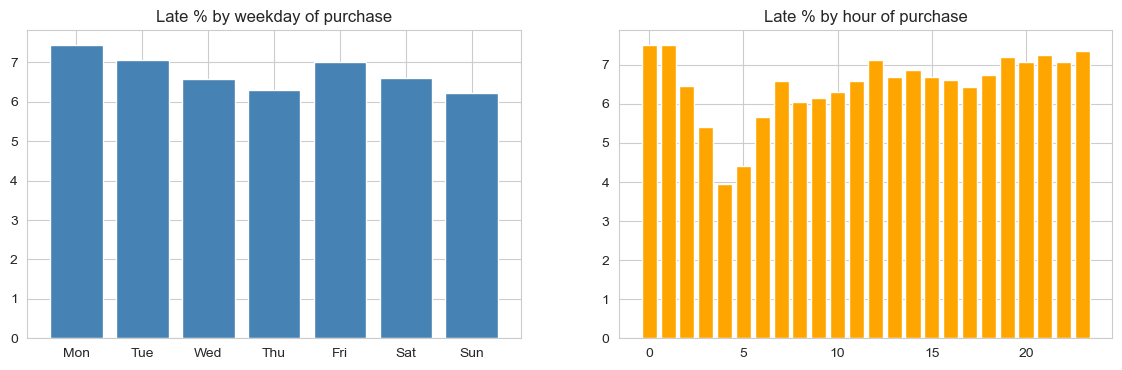

Mon    7.44
Tue    7.05
Wed    6.57
Thu    6.30
Fri    7.02
Sat    6.59
Sun    6.22
Name: is_late, dtype: float64


In [37]:
weekday_late = df.groupby('purchase_weekday')['is_late'].mean() * 100
weekday_late.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
hour_late = df.groupby('purchase_hour')['is_late'].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(weekday_late.index, weekday_late.values, color='steelblue')
ax[0].set_title('Late % by weekday of purchase')
ax[1].bar(hour_late.index, hour_late.values, color='orange')
ax[1].set_title('Late % by hour of purchase')
plt.show()

print(weekday_late.round(2))

## Section 8: Distance between seller and customer

**What:** Histogram of the distance in km.
**Why:** Shows how far packages usually travel.
**Watch out:** orders with missing zip coordinates have no distance and are not drawn.

Orders without distance: 486


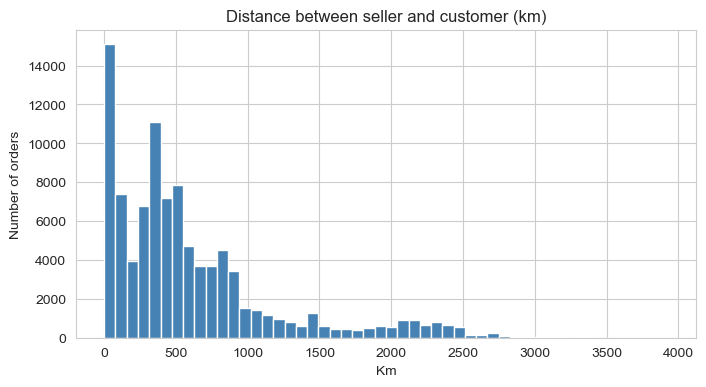

count    95984.0
mean       600.4
std        592.4
min          0.0
25%        185.9
50%        433.8
75%        798.3
max       3927.4
Name: distance_km, dtype: float64


In [38]:
print('Orders without distance:', df['distance_km'].isnull().sum())

plt.hist(df['distance_km'].dropna(), bins=50, color='steelblue')
plt.title('Distance between seller and customer (km)')
plt.xlabel('Km')
plt.ylabel('Number of orders')
plt.show()

print(df['distance_km'].describe().round(1))

**What:** Late % and average delivery days for each distance band.
**Why:** Tests directly if far deliveries are late more often.
**Watch out:** bands are fixed and easy to explain; the first band includes same-zip deliveries (distance 0).

                orders  late_pct  avg_days
distance_group                            
0-100            17904      4.45      6.51
100-300          13336      5.20     10.00
300-600          31491      6.74     12.62
600-1000         17904      7.09     14.71
1000-2000         9743      9.55     17.97
2000+             5606     12.08     21.17


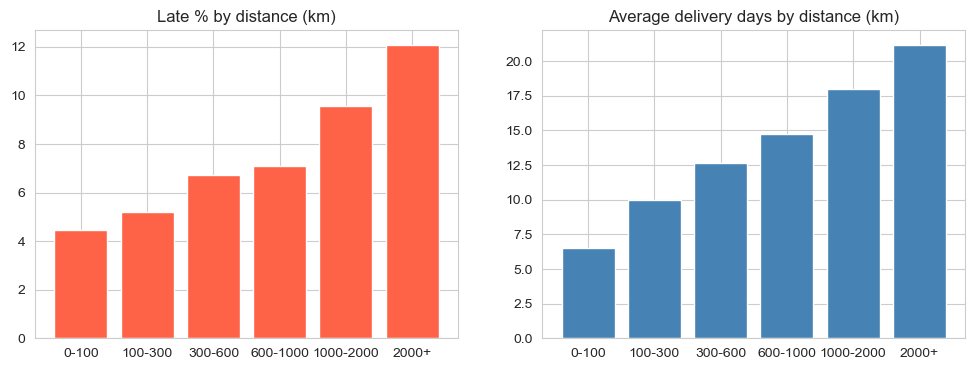

In [39]:
df['distance_group'] = pd.cut(df['distance_km'], bins=[-1, 100, 300, 600, 1000, 2000, 10000], labels=['0-100', '100-300', '300-600', '600-1000', '1000-2000', '2000+'])

dist_late = df.groupby('distance_group', observed=True).agg(orders=('is_late', 'count'), late_pct=('is_late', 'mean'), avg_days=('delivery_days', 'mean'))
dist_late['late_pct'] = dist_late['late_pct'] * 100
print(dist_late.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(dist_late.index.astype(str), dist_late['late_pct'], color='tomato')
ax[0].set_title('Late % by distance (km)')
ax[1].bar(dist_late.index.astype(str), dist_late['avg_days'], color='steelblue')
ax[1].set_title('Average delivery days by distance (km)')
plt.show()

## Section 9: Correlation

**What:** Heatmap of correlations between is_late and the columns that are known at purchase time.
**Why:** Shows which numeric columns move together with lateness.
**Watch out:** correlation is a straight-line measure and does not prove cause. We leave out columns known only after delivery (they would be leakage).

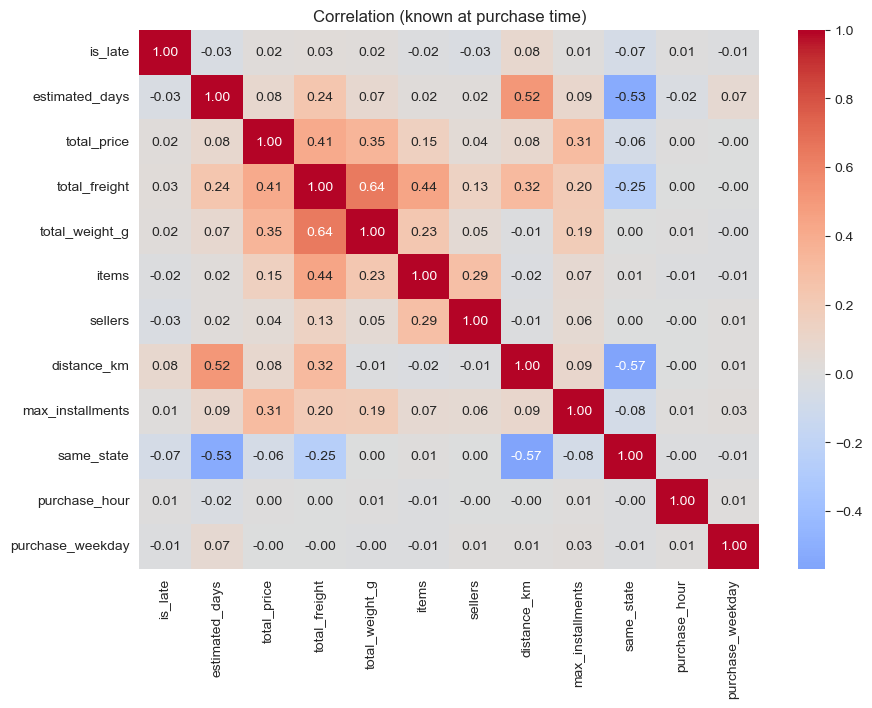

distance_km         0.076
total_freight       0.031
total_weight_g      0.020
total_price         0.018
max_installments    0.013
purchase_hour       0.007
purchase_weekday   -0.012
items              -0.015
sellers            -0.026
estimated_days     -0.033
same_state         -0.068
Name: is_late, dtype: float64

In [40]:
corr_cols = ['is_late', 'estimated_days', 'total_price', 'total_freight', 'total_weight_g', 'items', 'sellers', 'distance_km', 'max_installments', 'same_state', 'purchase_hour', 'purchase_weekday']
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation (known at purchase time)')
plt.show()

corr['is_late'].drop('is_late').sort_values(ascending=False).round(3)

## Section 10: Business impact

**What:** Average review score and score distribution for late and on-time orders.
**Why:** Shows the cost of a late delivery for the customer experience.
**Watch out:** reviews exist for almost every delivered order, but a few have no review (they are left out of the average).

is_late
0    4.29
1    2.27
Name: review_score, dtype: float64


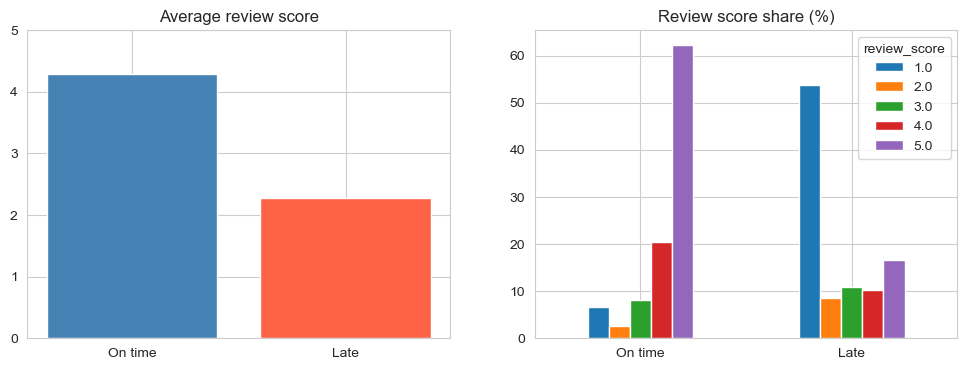

In [41]:
avg_score = df.groupby('is_late')['review_score'].mean()
print(avg_score.round(2))

score_share = pd.crosstab(df['is_late'], df['review_score'], normalize='index') * 100
score_share.index = ['On time', 'Late']

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(['On time', 'Late'], avg_score.values, color=['steelblue', 'tomato'])
ax[0].set_title('Average review score')
ax[0].set_ylim(0, 5)
score_share.plot(kind='bar', ax=ax[1])
ax[1].set_title('Review score share (%)')
ax[1].tick_params(axis='x', rotation=0)
plt.show()

## Section 11: Hand-off to the ML phase

**What:** Count the rows we will exclude in the ML table (impossible dates, missing data).
**Why:** In EDA we kept every order. The ML table must be clean, and we should know how many rows this removes.
**Watch out:** these are real orders. Dropping them is only for the model, not for the business analysis.

In [42]:
print('Pickup before purchase:', (df['order_delivered_carrier_date'] < df['order_purchase_timestamp']).sum())
print('Delivered before pickup:', (df['order_delivered_customer_date'] < df['order_delivered_carrier_date']).sum())
print('No pickup date:', df['order_delivered_carrier_date'].isnull().sum())
print('Order without items:', df['items'].isnull().sum())
print('No distance (missing zip):', df['distance_km'].isnull().sum())
print('Delivered orders with no delivery date (already excluded):', ((orders['order_status'] == 'delivered') & (orders['order_delivered_customer_date'].isnull())).sum())

Pickup before purchase: 165
Delivered before pickup: 23
No pickup date: 1
Order without items: 0
No distance (missing zip): 486
Delivered orders with no delivery date (already excluded): 8


**What:** Save the EDA table as a CSV.
**Why:** The next phase builds the ML table from it, and you can reuse it in Power BI.
**Watch out:** index=False avoids an extra index column.

In [43]:
df.to_csv('eda_orders_master.csv', index=False)
print('Saved eda_orders_master.csv', df.shape)

Saved eda_orders_master.csv (96470, 47)


## Section 12: Findings summary

**1. The target is rare.** 6.77% of delivered orders are late (6,534 of 96,470). 78.9% arrive at least 7 days early. Average delivery is 12.56 days (median 10.22) against 23.74 days promised, so the promise has a big safety margin. Late orders are late by 7 days at the median, and 2,862 orders (3.0% of all) are 8+ days late.

**2. Where the delay happens.** Late orders wait 5.57 days for carrier pickup (on-time: 2.65) and then spend 27.88 days in transit (on-time: 8.00). The carrier leg is the biggest difference (about 3.5 times longer). Seller handling also matters: 22.34% of late orders were handed to the carrier after the shipping limit date, against 4.57% of on-time orders. When the seller is late, the order is late 26.19% of the time, against 5.58% when the seller is on time.

**3. Geography is a strong driver.** Customer states: AL 21.41%, MA 17.43%, SE 15.22% versus PR 4.04% and SP 4.49%. Different-state orders are late 8.05% of the time and take 15.15 days; same-state orders 4.50% and 7.95 days. Seller state MA is the worst (19.07%, 388 orders).

**4. Distance is a strong driver.** Late % rises from 4.45% (0-100 km) to 12.08% (2,000+ km), and average delivery days from 6.51 to 21.17.

**5. Time matters (events).** Late % peaks in Nov 2017 (12.40%), Feb 2018 (14.13%) and Mar 2018 (18.96%), while Jun 2018 has only 1.16%. Weekday and hour show only small differences (Mon 7.44% vs Sun 6.22%).

**6. Order attributes have a weak effect.** Late % grows slowly with price (6.03% to 8.08%), freight (4.26% to 8.61%) and weight (6.53% to 7.79%). Multi-item orders are slightly less late (6.94% for 1 item, 5.04% for 3+). Payment type shows little difference (boleto 7.32%, debit card 5.37%). A few categories look high (audio 11.92%, home_confort 9.46%) but they have only about 350 orders each.

**7. Outliers are real, not errors.** There are 7,658 price outliers (8.08% late versus 6.66% for the rest), 9,694 freight outliers (8.50% versus 6.58%) and 13,544 weight outliers (7.67% versus 6.63%). They carry a little information, so we keep them.

**8. Correlations are weak.** The strongest numeric link to is_late is distance_km (0.076), then same_state (-0.068). Lateness is not explained by one straight-line column. It comes from combinations (region, distance, time period), so expect a tree-based model to beat a simple linear one, and expect moderate (not perfect) performance.

**9. The promise already contains distance.** estimated_days is correlated with distance_km (0.52), so Olist's own estimate already knows about distance. The model has to find what the estimate misses (peak months, slow regions, slow sellers).

**10. Business impact.** Average review is 4.29 for on-time orders and 2.27 for late orders. 53.8% of late orders get 1 star, against 6.6% of on-time orders.

### Hand-off to the ML phase

**Candidate features (all known at purchase time):** customer_state, seller_state, same_state, distance_km, estimated_days, total_price, total_freight, total_weight_g, items, sellers, category, payment_type, max_installments, purchase month, weekday and hour.

**Leakage list (never give these to the model, they are known only after the order ships or arrives):** delivery_days, delay_days, order_delivered_customer_date, order_delivered_carrier_date, order_approved_at, the three stage times, seller_late_handover, review_score and the review dates.

**Rows to exclude in the ML table (real orders, dropped only for the model):** 165 with pickup before purchase, 23 delivered before pickup, 1 with no pickup date, and 486 with no distance (missing zip). That is about 675 rows (0.7%). The SQL phase counted 166 for pickup before purchase because it looked at all orders, not only delivered ones.

**Metric choice:** the target is imbalanced (6.77%), so we judge the model with recall, precision, F1 and ROC-AUC, not plain accuracy.